# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import math


## 1. Régression linéaire

In [ ]:
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)
#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)


# On défini les différentes transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=5000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 5
            ngram_range=(1,2), # Capte les expressions de 2 mots
            stop_words='english'), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

reg = model.fit(X=x_train,y=y_train)

prediction = reg.predict(x_test)



Processeur : passthrough


ValueError: For a sparse output, all columns should be a numeric or convertible to a numeric.

Mse: 1.9846753498042864
RMSE: 1.4087850616060231


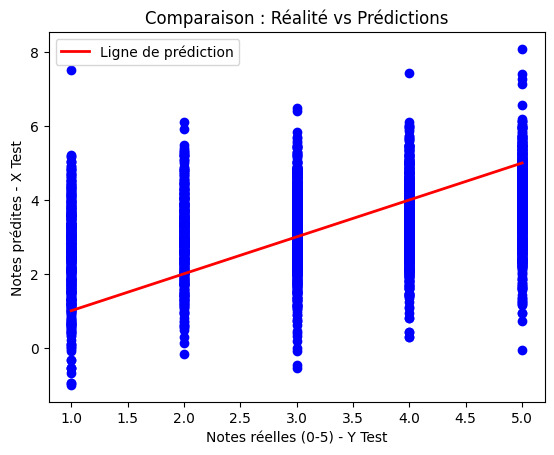

In [ ]:
# Mse
mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")

plt.scatter(y_test, prediction,color="blue")
plt.plot([1,5], [1,5], color="red", lw=2, label="Ligne de prédiction")

plt.xlabel("Notes réelles (0-5) - Y Test")
plt.ylabel("Notes prédites - X Test")
plt.title("Comparaison : Réalité vs Prédictions")
plt.legend()
plt.show()

## 2. Synthèse des expérimentations et des résultats obtenus